# Assignment 2: Thailand Air Quality Classification Analysis

**การจำแนกระดับความเสี่ยงด้านคุณภาพอากาศจากค่า PM2.5 ของวันถัดไป**

- ชุดข้อมูล: `Air_Quality_Dataset (1).xlsx` ชีต `Air_Quality_Data`
- ช่วงเวลาที่ศึกษา: ปี 2025 จากสถานีตรวจวัด 18 สถานี
- ตัวแปรเป้าหมาย: `Risk_Level` ของวันถัดไป โดยอ้างอิงค่า PM2.5 ของสถานีเดียวกัน
- โมเดลที่ใช้: Decision Tree Classification และ K-Nearest Neighbors (KNN)

กำหนดระดับความเสี่ยงจากค่า PM2.5 ของวันถัดไป ได้แก่ **Low** เมื่อค่าไม่เกิน 15 µg/m³, **Moderate** เมื่อค่ามากกว่า 15 และไม่เกิน 37.5 µg/m³ และ **High** เมื่อค่ามากกว่า 37.5 µg/m³

**ข้อกำหนดสำคัญ:** ไม่ใช้ค่า PM2.5 หรือ AQI เป็นตัวแปรอิสระในการพยากรณ์ เพื่อป้องกัน Data Leakage

## ขอบเขตและวิธีการวิเคราะห์

วิเคราะห์ข้อมูลคุณภาพอากาศรายวันเพื่อสร้างตัวแปรเป้าหมายจากค่า PM2.5 ของวันถัดไปในสถานีเดียวกัน โดยใช้ตัวแปรสภาพอากาศและข้อมูลภูมิภาค/เดือนจำนวน 6 ตัวแปรเป็นข้อมูลนำเข้า

แบ่งข้อมูลตามลำดับเวลา โดยใช้ข้อมูลเดือนมกราคม–กันยายน 2025 สำหรับฝึกโมเดล และข้อมูลเดือนตุลาคม–ธันวาคม 2025 สำหรับทดสอบ จากนั้นพัฒนาโมเดล Decision Tree และ KNN เปรียบเทียบประสิทธิภาพด้วย Accuracy, Macro F1-score, Precision, Recall และ Confusion Matrix รวมถึงแปลผล Feature Importance และข้อจำกัดของโมเดล

### ข้อมูลที่ใช้และการตรวจสอบเบื้องต้น

อ่านข้อมูลจากชีต `Air_Quality_Data` ซึ่งมีข้อมูลรายวัน 6,570 รายการ จาก 18 สถานี และ 14 คอลัมน์ ตัวแปร `Humidity_Pct` มีค่าสูญหาย 37 ค่า และ `Wind_Speed_kmh` มีค่าสูญหาย 30 ค่า ส่วนตัวแปรสภาพอากาศเชิงตัวเลขจะได้รับการจัดการค่าสูญหายภายใน Pipeline โดยเรียนรู้ค่าทดแทนจากชุด Training เท่านั้น

In [1]:
%matplotlib inline
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})


from pathlib import Path

# ใส่ไฟล์ Excel ในโฟลเดอร์เดียวกับ Notebook (หรืออัปโหลดใน Colab)
candidates = [
    Path("Air_Quality_Dataset (1).xlsx"),
    Path("Air_Quality_Dataset.xlsx"),
    Path("/content/Air_Quality_Dataset (1).xlsx"),
    Path("/content/Air_Quality_Dataset.xlsx"),
    Path("/mnt/data/Air_Quality_Dataset (1).xlsx"),
]
file_path = next((p for p in candidates if p.exists()), None)
if file_path is None:
    discovered = sorted(Path(".").glob("Air_Quality_Dataset*.xlsx"))
    file_path = discovered[0] if discovered else None
if file_path is None:
    raise FileNotFoundError("ไม่พบ Excel: กรุณาอัปโหลด Air_Quality_Dataset (1).xlsx แล้วรันใหม่")

print("ใช้ไฟล์:", file_path)

data = pd.read_excel(file_path, sheet_name="Air_Quality_Data", parse_dates=["Date"])
print("Shape:", data.shape)
print("Null by column:")
display(data.isna().sum().to_frame("Missing_Count"))
display(data.head())

ใช้ไฟล์: Air_Quality_Dataset (1).xlsx


Shape: (6570, 14)
Null by column:


,Missing_Count
Date,0
Station_ID,0
Station_Name,0
Province,0
Region,0
Latitude,0
Longitude,0
PM2_5_ug_m3,0
PM10_ug_m3,0
AQI,0


,Date,Station_ID,Station_Name,Province,Region,Latitude,Longitude,PM2_5_ug_m3,PM10_ug_m3,AQI,Temperature_C,Humidity_Pct,Wind_Speed_kmh,Rainfall_mm
0,2025-01-01,BKK01,Bangkok Central,Bangkok,Central,13.7563,100.5018,59.7,83.9,118,23.7,70.6,7.9,0.0
1,2025-01-01,NPT01,Nakhon Pathom,Nakhon Pathom,Central,13.8199,100.0622,25.3,41.9,46,26.0,79.8,12.8,0.0
2,2025-01-01,AYA01,Ayutthaya,Phra Nakhon Si Ayutthaya,Central,14.3532,100.5689,22.6,43.5,45,25.3,80.8,8.5,1.3
3,2025-01-01,SKN01,Samut Sakhon,Samut Sakhon,Central,13.5475,100.2744,36.4,57.2,75,24.4,74.2,9.2,0.0
4,2025-01-01,CNX01,Chiang Mai City,Chiang Mai,North,18.7883,98.9853,28.6,37.6,59,22.1,72.5,10.0,1.0


## ข้อ 1. การสร้างตัวแปรเป้าหมาย Risk_Level จากค่า PM2.5 ของวันถัดไป

จัดเรียงข้อมูลตาม `Station_ID` และ `Date` จากนั้นใช้การเลื่อนค่าภายในสถานีเดียวกันด้วย `groupby("Station_ID").shift(-1)` เพื่อสร้าง `Target_Date` และ `PM25_Next_Day` พร้อมคำนวณจำนวนวันระหว่างวันที่ของข้อมูลต้นทางกับวันที่เป้าหมาย

คงไว้เฉพาะรายการที่มีข้อมูลของวันถัดไปจริง โดยกำหนดให้ `Days_Ahead = 1` และตัดข้อมูลวันสุดท้ายของแต่ละสถานีออก เนื่องจากไม่มีข้อมูลวันถัดไปภายในชุดข้อมูล ผลที่ได้คือข้อมูลที่ใช้สร้างตัวแปรเป้าหมายจำนวน **6,552 รายการ** จากข้อมูลต้นทางที่ตัดออก 18 รายการ

กำหนดระดับความเสี่ยงจากค่า `PM25_Next_Day` ดังนี้

| ค่า PM2.5 ของวันถัดไป | Risk_Level |
|---|---|
| น้อยกว่าหรือเท่ากับ 15 µg/m³ | Low |
| มากกว่า 15 และน้อยกว่าหรือเท่ากับ 37.5 µg/m³ | Moderate |
| มากกว่า 37.5 µg/m³ | High |

การสร้างตัวแปรเป้าหมายใช้ข้อมูลของวันถัดไปจากสถานีเดียวกันเท่านั้น และตรวจสอบให้ระยะห่างระหว่างวันเท่ากับ 1 วัน

In [2]:
s = (data.sort_values(["Station_ID", "Date"])
         .drop_duplicates(["Station_ID", "Date"])
         .reset_index(drop=True).copy())
s["Target_Date"] = s.groupby("Station_ID")["Date"].shift(-1)
s["PM25_Next_Day"] = s.groupby("Station_ID")["PM2_5_ug_m3"].shift(-1)
s["Days_Ahead"] = (s["Target_Date"] - s["Date"]).dt.days

# คงเฉพาะรายการที่มีวันถัดไปจริงภายในสถานีเดียวกัน
model_df = s.loc[(s["Days_Ahead"] == 1) & s["PM25_Next_Day"].notna()].copy()
model_df["Risk_Level"] = pd.cut(
    model_df["PM25_Next_Day"],
    bins=[-np.inf, 15, 37.5, np.inf],
    labels=["Low", "Moderate", "High"],
    include_lowest=True
).astype(str)
model_df["Month"] = model_df["Date"].dt.month

print("ข้อมูลที่สามารถสร้าง target วันถัดไปได้:", len(model_df), "แถว")
print("ตัดแถวท้ายสถานี/วันขาดช่วงออก:", len(s) - len(model_df), "แถว")
display(model_df[["Station_ID", "Date", "Target_Date", "PM2_5_ug_m3", "PM25_Next_Day", "Risk_Level"]].head(12))
assert (model_df["Days_Ahead"] == 1).all()
assert len(model_df) == 18 * 364  # แต่ละสถานีมีข้อมูล 365 วัน จึงเกิดคู่วันติดกัน 364 คู่

ข้อมูลที่สามารถสร้าง target วันถัดไปได้: 6552 แถว
ตัดแถวท้ายสถานี/วันขาดช่วงออก: 18 แถว


,Station_ID,Date,Target_Date,PM2_5_ug_m3,PM25_Next_Day,Risk_Level
0,AYA01,2025-01-01,2025-01-02,22.6,14.6,Low
1,AYA01,2025-01-02,2025-01-03,14.6,29.7,Moderate
2,AYA01,2025-01-03,2025-01-04,29.7,27.2,Moderate
3,AYA01,2025-01-04,2025-01-05,27.2,31.9,Moderate
4,AYA01,2025-01-05,2025-01-06,31.9,38.3,High
5,AYA01,2025-01-06,2025-01-07,38.3,40.8,High
6,AYA01,2025-01-07,2025-01-08,40.8,29.6,Moderate
7,AYA01,2025-01-08,2025-01-09,29.6,27.5,Moderate
8,AYA01,2025-01-09,2025-01-10,27.5,29.1,Moderate
9,AYA01,2025-01-10,2025-01-11,29.1,37.3,Moderate


## ข้อ 2. การคัดเลือกตัวแปรอิสระและการป้องกัน Data Leakage

กำหนดตัวแปรอิสระ (Predictors) จำนวน 6 ตัวแปร ได้แก่

1. `Temperature_C` — อุณหภูมิ
2. `Humidity_Pct` — ความชื้นสัมพัทธ์
3. `Wind_Speed_kmh` — ความเร็วลม
4. `Rainfall_mm` — ปริมาณน้ำฝน
5. `Region` — ภูมิภาค
6. `Month` — เดือน

ไม่ใช้ `PM2_5_ug_m3`, `PM25_Next_Day`, `AQI` และ `Target_Date` เป็นตัวแปรอิสระ โดย `PM25_Next_Day` ใช้สำหรับสร้างคำตอบเป้าหมาย `Risk_Level` เท่านั้น จึงไม่ถูกนำเข้าสู่ชุดตัวแปร `X`

ตรวจสอบขอบเขตการแบ่งระดับความเสี่ยงด้วยค่าตัวอย่าง ได้แก่ PM2.5 เท่ากับ 15.00 เป็น Low, 15.01 เป็น Moderate, 37.50 เป็น Moderate และ 37.51 เป็น High

In [3]:
labels_order = ["Low", "Moderate", "High"]
edge_example = pd.Series([15.00, 15.01, 37.50, 37.51], name="PM25_next")
edge_label = pd.cut(edge_example, bins=[-np.inf, 15, 37.5, np.inf],
                    labels=labels_order, include_lowest=True)
display(pd.DataFrame({"Next_Day_PM25": edge_example, "Expected_Risk": edge_label.astype(str)}))

features = ["Temperature_C", "Humidity_Pct", "Wind_Speed_kmh", "Rainfall_mm", "Region", "Month"]
numeric_features = ["Temperature_C", "Humidity_Pct", "Wind_Speed_kmh", "Rainfall_mm", "Month"]
cat_features = ["Region"]
assert len(features) == 6
assert not (set(features) & {"PM2_5_ug_m3", "PM25_Next_Day", "AQI", "Target_Date", "Risk_Level"})
print("Predictors ทั้ง 6:", features)
print("ความถี่ Risk_Level ทั้งปี:")
display(model_df["Risk_Level"].value_counts().reindex(labels_order, fill_value=0).to_frame("Count"))

,Next_Day_PM25,Expected_Risk
0,15.00,Low
1,15.01,Moderate
2,37.50,Moderate
3,37.51,High


Predictors ทั้ง 6: ['Temperature_C', 'Humidity_Pct', 'Wind_Speed_kmh', 'Rainfall_mm', 'Region', 'Month']
ความถี่ Risk_Level ทั้งปี:


,Count
Risk_Level,
Low,3446
Moderate,2427
High,679


## ข้อ 3. การแบ่งข้อมูลตามลำดับเวลา (Chronological Train/Test Split)

แบ่งข้อมูลโดยไม่สุ่ม เพื่อรักษาลำดับเวลาตามข้อกำหนดของการพยากรณ์

- **Training Set:** วันที่ของตัวแปรอิสระอยู่ระหว่าง 1 มกราคม–29 กันยายน 2025 จำนวน **4,896 รายการ** โดยวันที่เป้าหมายสุดท้ายอยู่ที่ 30 กันยายน 2025
- **Testing Set:** วันที่ของตัวแปรอิสระอยู่ระหว่าง 1 ตุลาคม–30 ธันวาคม 2025 จำนวน **1,638 รายการ** โดยวันที่เป้าหมายอยู่ระหว่าง 2 ตุลาคม–31 ธันวาคม 2025

ข้อมูลวันที่ 30 กันยายน 18 รายการถูกกันออกจาก Training เนื่องจากค่าเป้าหมายเป็นวันที่ 1 ตุลาคม ซึ่งอยู่ในช่วง Testing จึงไม่ให้ข้อมูลเป้าหมายของช่วงทดสอบย้อนกลับไปอยู่ในชุดฝึก ส่วนข้อมูลวันที่ 31 ธันวาคมของแต่ละสถานีไม่สามารถสร้างเป้าหมายวันถัดไปได้ จึงถูกตัดออกตั้งแต่การสร้าง Target

การกระจายของระดับความเสี่ยงแตกต่างกันระหว่างชุดข้อมูล ได้แก่ Training มี Low 2,424 รายการ, Moderate 1,799 รายการ และ High 673 รายการ ส่วน Testing มี Low 1,011 รายการ, Moderate 621 รายการ และ High เพียง 6 รายการ

In [4]:
train_end = pd.Timestamp("2025-09-30")
test_start = pd.Timestamp("2025-10-01")
train = model_df[(model_df["Date"] <= train_end) & (model_df["Target_Date"] <= train_end)].copy()
test = model_df[(model_df["Date"] >= test_start) & (model_df["Date"] <= pd.Timestamp("2025-12-31"))].copy()

X_train, y_train = train[features], train["Risk_Level"]
X_test, y_test = test[features], test["Risk_Level"]
print("Train:", len(train), "rows | dates", train["Date"].min().date(), "to", train["Date"].max().date())
print("Test:", len(test), "rows | dates", test["Date"].min().date(), "to", test["Date"].max().date())
print("วันที่ label สุดท้ายของ Train:", train["Target_Date"].max().date())
print("วันที่ label แรกของ Test:", test["Target_Date"].min().date())
print("แถวกัน leakage ที่ Train/Test boundary:", len(model_df) - len(train) - len(test))
assert len(train) == 4896 and len(test) == 1638
assert train["Target_Date"].max() < test["Date"].min()
print("Distribution by split (count):")
class_counts = pd.DataFrame({
    "Train": y_train.value_counts().reindex(labels_order, fill_value=0),
    "Test": y_test.value_counts().reindex(labels_order, fill_value=0)
})
display(class_counts)
print("Distribution by split (%):")
display(class_counts.div(class_counts.sum(axis=0), axis=1).mul(100).round(2))

Train: 4896 rows | dates 2025-01-01 to 2025-09-29
Test: 1638 rows | dates 2025-10-01 to 2025-12-30
วันที่ label สุดท้ายของ Train: 2025-09-30
วันที่ label แรกของ Test: 2025-10-02
แถวกัน leakage ที่ Train/Test boundary: 18
Distribution by split (count):


,Train,Test
Risk_Level,,
Low,2424,1011
Moderate,1799,621
High,673,6


Distribution by split (%):


,Train,Test
Risk_Level,,
Low,49.51,61.72
Moderate,36.74,37.91
High,13.75,0.37


### การเตรียมข้อมูลด้วย Pipeline

ใช้ `ColumnTransformer` และ `Pipeline` เพื่อจัดการข้อมูลก่อนเข้าสู่โมเดล โดยเรียนรู้ค่าการเตรียมข้อมูลจาก Training Set เท่านั้น แล้วจึงนำตัวแปลงชุดเดิมไปใช้กับ Testing Set

- ตัวแปรเชิงตัวเลข 5 ตัว ได้แก่ Temperature, Humidity, Wind Speed, Rainfall และ Month ใช้ค่ามัธยฐาน (Median) เติมค่าสูญหาย
- ตัวแปรเชิงกลุ่ม `Region` ใช้ค่าที่พบบ่อยที่สุดเติมค่าสูญหาย และแปลงด้วย One-Hot Encoding
- สำหรับ KNN ปรับมาตราส่วนตัวแปรเชิงตัวเลขด้วย StandardScaler เนื่องจาก KNN ใช้ระยะทางในการหาความใกล้เคียง
- สำหรับ Decision Tree ไม่จำเป็นต้องปรับมาตราส่วน เนื่องจากต้นไม้ตัดสินใจแบ่งข้อมูลด้วยเงื่อนไขของตัวแปร

แม้หลัง One-Hot Encoding จะมีคอลัมน์ที่โมเดลใช้มากกว่า 6 คอลัมน์ แต่ตัวแปรอิสระต้นฉบับยังคงมี 6 ตัวตามข้อกำหนด

In [5]:
# แต่ละโมเดลใช้ preprocess ของตัวเอง เพื่อให้ KNN ได้สเกลที่เหมาะสม
preprocess_tree = ColumnTransformer(transformers=[
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_features)
])
preprocess_knn = ColumnTransformer(transformers=[
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_features)
])
print("Created separate preprocessing pipelines. No fit on test data.")

Created separate preprocessing pipelines. No fit on test data.


## ข้อ 4. การพัฒนาโมเดลจำแนกประเภท (Classification Model Development)

พัฒนาโมเดล 2 วิธี ได้แก่

**1) Decision Tree Classifier**

ใช้ `DecisionTreeClassifier` โดยกำหนด `max_depth=5`, `min_samples_leaf=5`, `class_weight="balanced"` และ `random_state=42` เพื่อจำกัดความซับซ้อนของต้นไม้ ลดการเรียนรู้รายละเอียดเฉพาะชุดฝึกมากเกินไป และเพิ่มน้ำหนักให้กลุ่มที่มีจำนวนตัวอย่างน้อย

**2) K-Nearest Neighbors (KNN) Classifier**

ใช้ `KNeighborsClassifier` โดยกำหนด `n_neighbors=11` และ `weights="distance"` เพื่อให้ตัวอย่างที่อยู่ใกล้มีอิทธิพลต่อการจำแนกมากกว่าตัวอย่างที่อยู่ไกล โดยใช้ข้อมูลที่ผ่านการปรับมาตราส่วนแล้ว

ทั้งสองโมเดลถูกฝึกด้วย Training Set และนำไปทำนาย Testing Set จำนวน 1,638 รายการ โดยไม่ได้ใช้ข้อมูล Testing ในการเรียนรู้ Pipeline หรือฝึกโมเดล

In [6]:
models = {
    "Decision Tree": Pipeline(steps=[
        ("preprocess", preprocess_tree),
        ("classifier", DecisionTreeClassifier(
            max_depth=5, min_samples_leaf=5, class_weight="balanced", random_state=42
        ))
    ]),
    "KNN": Pipeline(steps=[
        ("preprocess", preprocess_knn),
        ("classifier", KNeighborsClassifier(n_neighbors=11, weights="distance"))
    ])
}
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)            # เรียนรู้เฉพาะ Training
    predictions[name] = model.predict(X_test)  # ทำนาย Testing ที่ยังไม่ได้เห็น
    print(f"Trained {name}. Predictions: {len(predictions[name]):,}")

Trained Decision Tree. Predictions: 1,638
Trained KNN. Predictions: 1,638


## ข้อ 5. การประเมินและเปรียบเทียบประสิทธิภาพของโมเดล

ประเมินผลด้วย Accuracy, Macro F1-score, Macro Precision, Macro Recall รวมถึง Precision, Recall และ F1-score เฉพาะกลุ่ม High เพื่อพิจารณาความสามารถในการตรวจจับกลุ่มความเสี่ยงสูง

| ตัวชี้วัด | Decision Tree | KNN |
|---|---:|---:|
| Accuracy | 0.7534 | 0.6722 |
| Macro F1-score | 0.4931 | 0.4040 |
| Macro Precision | 0.4922 | 0.4384 |
| Macro Recall | 0.4940 | 0.4069 |
| High Precision | 0.0000 | 0.0000 |
| High Recall | 0.0000 | 0.0000 |
| High F1-score | 0.0000 | 0.0000 |

จากผลการประเมิน Decision Tree มี Accuracy และ Macro F1-score สูงกว่า KNN ในชุด Testing อย่างไรก็ตาม ทั้งสองโมเดลมีค่า High Recall เท่ากับ 0 แสดงว่ายังไม่สามารถตรวจจับตัวอย่าง High ในชุดทดสอบได้

In [7]:
rows = []
for name, y_pred in predictions.items():
    report = classification_report(y_test, y_pred, labels=labels_order,
                                   output_dict=True, zero_division=0)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro_F1": f1_score(y_test, y_pred, labels=labels_order, average="macro", zero_division=0),
        "Macro_Precision": precision_score(y_test, y_pred, labels=labels_order, average="macro", zero_division=0),
        "Macro_Recall": recall_score(y_test, y_pred, labels=labels_order, average="macro", zero_division=0),
        "High_Precision": report["High"]["precision"],
        "High_Recall": report["High"]["recall"],
        "High_F1": report["High"]["f1-score"],
        "Predicted_High": int((y_pred == "High").sum())
    })
comparison = pd.DataFrame(rows).set_index("Model")
print("Model performance on chronological Test set:")
display(comparison.round(4))
for name, pred in predictions.items():
    print("\n", name, "— Classification Report")
    print(classification_report(y_test, pred, labels=labels_order, zero_division=0))

Model performance on chronological Test set:


,Accuracy,Macro_F1,Macro_Precision,Macro_Recall,High_Precision,High_Recall,High_F1,Predicted_High
Model,,,,,,,,
Decision Tree,0.7534,0.4931,0.4922,0.4940,0.0,0.0,0.0,0
KNN,0.6722,0.4040,0.4384,0.4069,0.0,0.0,0.0,0



 Decision Tree — Classification Report
              precision    recall  f1-score   support

         Low       0.80      0.80      0.80      1011
    Moderate       0.67      0.68      0.68       621
        High       0.00      0.00      0.00         6

    accuracy                           0.75      1638
   macro avg       0.49      0.49      0.49      1638
weighted avg       0.75      0.75      0.75      1638


 KNN — Classification Report


              precision    recall  f1-score   support

         Low       0.68      0.88      0.77      1011
    Moderate       0.63      0.34      0.44       621
        High       0.00      0.00      0.00         6

    accuracy                           0.67      1638
   macro avg       0.44      0.41      0.40      1638
weighted avg       0.66      0.67      0.64      1638



### Confusion Matrix

Confusion Matrix แสดงจำนวนข้อมูลจริงเทียบกับผลการทำนาย โดยแถวแทนระดับความเสี่ยงจริง (True Label) และคอลัมน์แทนระดับความเสี่ยงที่โมเดลทำนาย (Predicted Label) ค่าบนแนวทแยงคือจำนวนรายการที่จำแนกได้ถูกต้อง ส่วนค่าที่อยู่นอกแนวทแยงคือจำนวนรายการที่จำแนกผิด

ในชุด Testing มีข้อมูลระดับ **High จำนวน 6 รายการจากทั้งหมด 1,638 รายการ หรือประมาณ 0.37%** ผลการทำนายพบว่า Decision Tree ตรวจจับ High ได้ 0 จาก 6 รายการ และ KNN ตรวจจับ High ได้ 0 จาก 6 รายการเช่นกัน

ดังนั้น แม้ Decision Tree จะมี Accuracy สูงกว่า แต่ยังไม่สามารถใช้ผลดังกล่าวยืนยันความสามารถในการแจ้งเตือนความเสี่ยงสูงได้

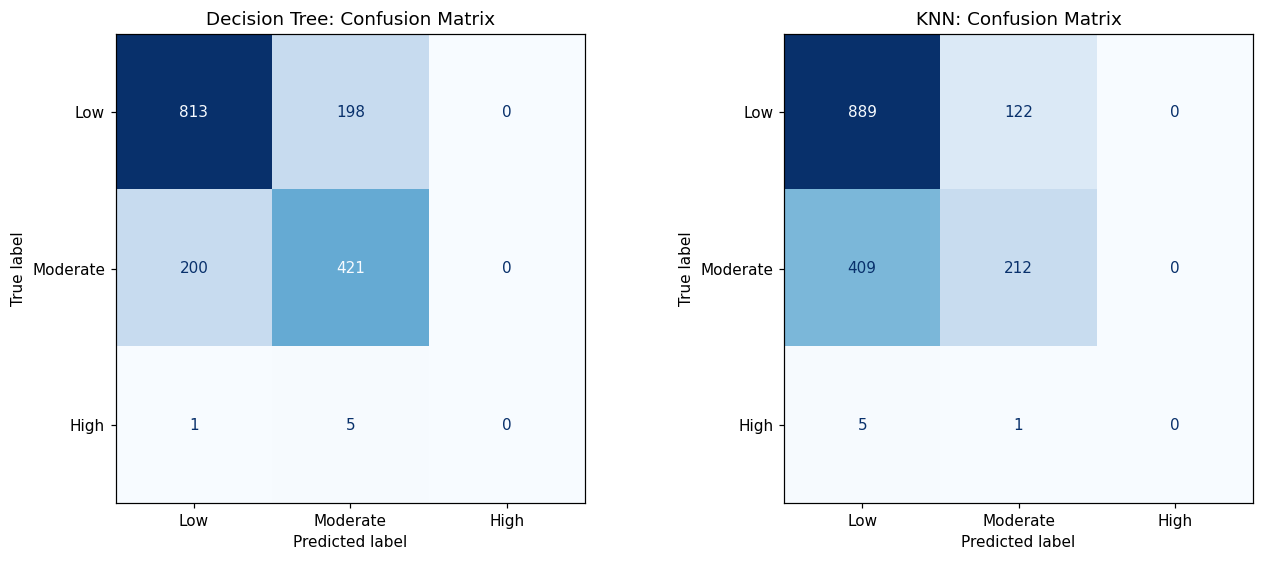

High cases in test: 6
Decision Tree: correctly detected High = 0 / 6
KNN: correctly detected High = 0 / 6


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=labels_order)
    ConfusionMatrixDisplay(cm, display_labels=labels_order).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{name}: Confusion Matrix")
plt.tight_layout()
plt.show()
print("High cases in test:", int((y_test == "High").sum()))
for name, pred in predictions.items():
    true_high_detected = int(((y_test.to_numpy() == "High") & (pred == "High")).sum())
    print(f"{name}: correctly detected High = {true_high_detected} / {(y_test == 'High').sum()}")

### การแปลผล Feature Importance ของ Decision Tree

วิเคราะห์ความสำคัญของตัวแปรจาก `feature_importances_` ของ Decision Tree โดยรวมคอลัมน์ One-Hot ของ `Region` กลับเป็นตัวแปรภูมิภาคเดียว เพื่อให้เปรียบเทียบกับตัวแปรอิสระต้นฉบับทั้ง 6 ตัวได้

| ตัวแปรอิสระ | Feature Importance |
|---|---:|
| Region | 0.5122 |
| Month | 0.4675 |
| Humidity_Pct | 0.0089 |
| Rainfall_mm | 0.0070 |
| Wind_Speed_kmh | 0.0039 |
| Temperature_C | 0.0004 |

ผลการวิเคราะห์พบว่า Region และ Month มีความสำคัญรวมกันประมาณ **0.9797 หรือ 97.97%** ของความสำคัญทั้งหมดในต้นไม้ที่ฝึก ขณะที่ตัวแปรสภาพอากาศอื่นมีค่าความสำคัญต่ำกว่า

Feature Importance เป็นการแสดงบทบาทของตัวแปรในการแบ่งโหนดของโมเดลที่ฝึกจากชุดข้อมูลนี้ ไม่ใช่หลักฐานยืนยันความสัมพันธ์เชิงเหตุและผล และอาจเปลี่ยนแปลงได้เมื่อใช้ข้อมูลหรือพารามิเตอร์ที่แตกต่างกัน

Decision Tree importance (encoded features):


,Encoded_Feature,Importance
0,num__Month,0.4675
1,cat__Region_North,0.2868
2,cat__Region_South,0.1335
3,cat__Region_East,0.0458
4,cat__Region_Central,0.0311
5,cat__Region_Northeast,0.0150
6,num__Humidity_Pct,0.0089
7,num__Rainfall_mm,0.0070
8,num__Wind_Speed_kmh,0.0039
9,num__Temperature_C,0.0004


Feature importance (6 original predictors):


,Original_Feature,Importance
3,Region,0.5122
1,Month,0.4675
0,Humidity_Pct,0.0089
2,Rainfall_mm,0.0070
5,Wind_Speed_kmh,0.0039
4,Temperature_C,0.0004


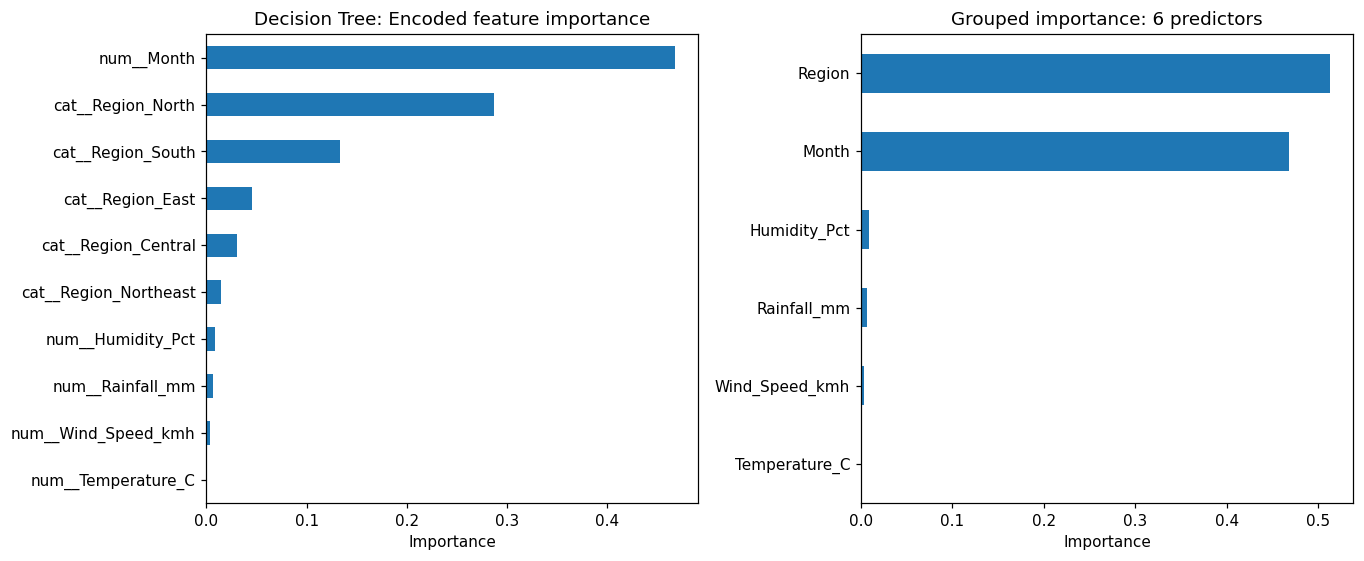

In [9]:
tree_pipe = models["Decision Tree"]
encoded_names = tree_pipe.named_steps["preprocess"].get_feature_names_out()
importance_values = tree_pipe.named_steps["classifier"].feature_importances_
imp = pd.DataFrame({"Encoded_Feature": encoded_names, "Importance": importance_values})
imp = imp.sort_values("Importance", ascending=False).reset_index(drop=True)
print("Decision Tree importance (encoded features):")
display(imp.round(4))

# รวม Region one-hot กลับมาเป็น predictor เดียว
imp["Original_Feature"] = imp["Encoded_Feature"].map(
    lambda name: "Region" if name.startswith("cat__Region_") else name.removeprefix("num__")
)
grouped_imp = imp.groupby("Original_Feature", as_index=False)["Importance"].sum()
grouped_imp = grouped_imp.sort_values("Importance", ascending=False)
print("Feature importance (6 original predictors):")
display(grouped_imp.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2))
imp.sort_values("Importance").plot.barh(x="Encoded_Feature", y="Importance", ax=axes[0], legend=False)
axes[0].set(title="Decision Tree: Encoded feature importance", xlabel="Importance", ylabel="")
grouped_imp.sort_values("Importance").plot.barh(x="Original_Feature", y="Importance", ax=axes[1], legend=False)
axes[1].set(title="Grouped importance: 6 predictors", xlabel="Importance", ylabel="")
plt.tight_layout()
plt.show()

### ข้อจำกัดของการวิเคราะห์

1. **Class Imbalance:** ชุด Testing มีข้อมูล High เพียง 6 จาก 1,638 รายการ หรือประมาณ 0.37% ทำให้การประเมินความสามารถในการตรวจจับ High มีข้อจำกัด และทั้งสองโมเดลตรวจไม่พบตัวอย่าง High ในชุดทดสอบ
2. **Distribution Shift:** Training มี High จำนวน 673 จาก 4,896 รายการ หรือประมาณ 13.75% แต่ Testing มี High เพียง 6 จาก 1,638 รายการ หรือประมาณ 0.37% แสดงว่าสัดส่วนระดับความเสี่ยงระหว่างช่วงเวลาฝึกและทดสอบแตกต่างกันมาก
3. **ข้อจำกัดในการพยากรณ์:** ตัวแปรอิสระตามโจทย์ประกอบด้วยสภาพอากาศ ภูมิภาค และเดือน โดยไม่ใช้ PM2.5 หรือ AQI จึงอาจไม่สามารถสะท้อนการเปลี่ยนแปลงของฝุ่นในวันถัดไปได้ครบถ้วน
4. **ข้อจำกัดของข้อมูล:** ชุดข้อมูลเป็นข้อมูลสังเคราะห์เพื่อการศึกษา ผลลัพธ์จึงไม่ควรนำไปใช้เป็นระบบแจ้งเตือนด้านสุขภาพหรือใช้แทนข้อมูลตรวจวัดจริง

นอกจากนี้ ควรพิจารณา Macro F1-score และ High Recall ร่วมกับ Accuracy เนื่องจาก Accuracy เพียงค่าเดียวอาจไม่สะท้อนความสามารถของโมเดลต่อกลุ่มที่มีจำนวนตัวอย่างน้อย

Risk_Level by month (count):

Risk_Level,Low,Moderate,High
Month,,,
1,140,311,107
2,90,209,205
3,122,227,209
4,181,232,127
5,307,228,23
6,385,154,1
7,412,146,0
8,427,131,0
9,371,168,1


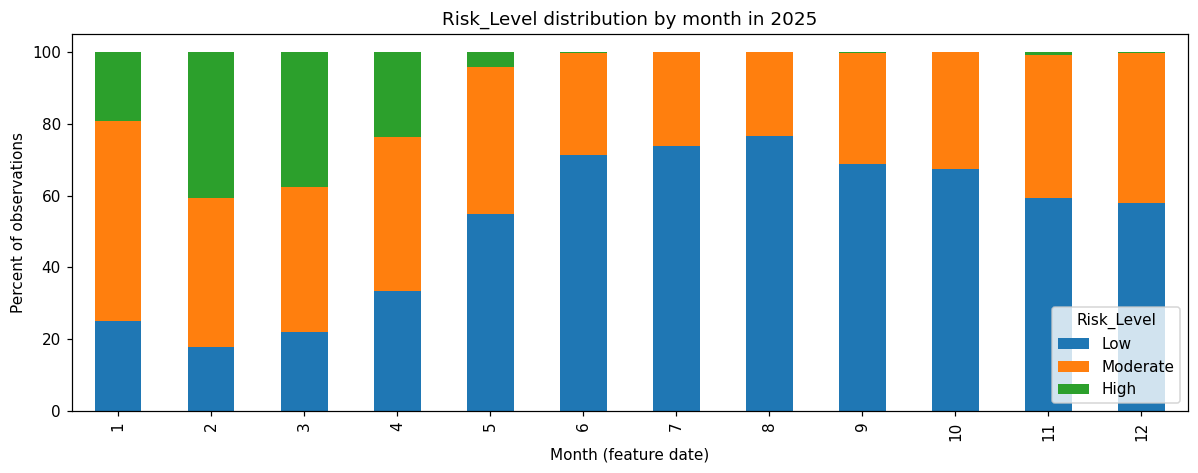

In [10]:
monthly_class = pd.crosstab(model_df["Month"], model_df["Risk_Level"])
monthly_class = monthly_class.reindex(index=range(1, 13), columns=labels_order, fill_value=0)
print("Risk_Level by month (count):")
display(monthly_class)
share = monthly_class.div(monthly_class.sum(axis=1), axis=0) * 100
ax = share.plot(kind="bar", stacked=True, figsize=(11, 4.4))
ax.set(title="Risk_Level distribution by month in 2025", xlabel="Month (feature date)", ylabel="Percent of observations")
ax.legend(title="Risk_Level")
plt.tight_layout()
plt.show()

### ข้อค้นพบสำคัญ (Key Insights)

1. **Decision Tree มีผลการประเมินโดยรวมสูงกว่า KNN:** Decision Tree มี Accuracy 75.34% และ Macro F1-score 0.4931 ขณะที่ KNN มี Accuracy 67.22% และ Macro F1-score 0.4040
2. **ทั้งสองโมเดลยังตรวจจับกลุ่ม High ไม่ได้:** ในชุด Testing มี High จริง 6 รายการ แต่ทั้ง Decision Tree และ KNN ทำนายถูก 0 รายการ จึงมี High Recall เท่ากับ 0
3. **ภูมิภาคและเดือนเป็นตัวแปรสำคัญของ Decision Tree:** Region มี Feature Importance 0.5122 และ Month มีค่า 0.4675 สะท้อนว่ารูปแบบความเสี่ยงในชุดข้อมูลนี้สัมพันธ์กับภูมิภาคและช่วงเวลาที่ใช้ฝึกโมเดลมากกว่าตัวแปรสภาพอากาศอื่นในต้นไม้ที่ได้
4. **ระดับความเสี่ยงเปลี่ยนแปลงตามเดือน:** ข้อมูลรายเดือนแสดงจำนวน High สูงในเดือนกุมภาพันธ์และมีนาคม ขณะที่เดือนกรกฎาคมและสิงหาคมไม่พบ High ในชุดข้อมูลตลอดปี 2025

### ข้อเสนอแนะ (Recommendations)

1. **เพิ่มข้อมูลที่ครอบคลุมหลายปีและหลายฤดูกาล:** โดยเฉพาะข้อมูลช่วงที่มีความเสี่ยงสูง เพื่อให้โมเดลเรียนรู้รูปแบบ High ได้จากตัวอย่างที่เพียงพอและหลากหลาย
2. **ประเมินโมเดลโดยเน้น High Recall และ Macro F1-score:** ใช้การตรวจสอบแบบลำดับเวลา เช่น Walk-forward Validation และพิจารณาวิธีจัดการ Class Imbalance ภายในชุด Training โดยไม่ปรับแต่งจากชุด Testing
3. **ใช้ข้อมูลตรวจวัดจริงประกอบการเฝ้าระวัง:** ในระหว่างที่โมเดลยังตรวจจับ High ไม่ได้ ไม่ควรใช้ผลทำนายจากโมเดลเพียงอย่างเดียวในการตัดสินใจหรือแจ้งเตือน

## สรุปผลการวิเคราะห์

การทดลองสร้างตัวแปร Risk_Level จากค่า PM2.5 ของวันถัดไปในสถานีเดียวกัน และใช้ตัวแปรอิสระ 6 ตัวตามข้อกำหนด โดยแบ่งข้อมูลตามลำดับเวลาเป็น Training 4,896 รายการ และ Testing 1,638 รายการ

เมื่อเปรียบเทียบโมเดลพบว่า Decision Tree มีผล Accuracy และ Macro F1-score สูงกว่า KNN อย่างไรก็ตาม ทั้งสองโมเดลไม่สามารถตรวจจับตัวอย่าง High ในชุด Testing ได้ จึงยังไม่เหมาะสำหรับใช้เป็นระบบแจ้งเตือนความเสี่ยงสูงโดยลำพัง ควรเพิ่มข้อมูลที่ครอบคลุมช่วงเวลาและระดับความเสี่ยงที่หลากหลาย รวมถึงประเมินโมเดลด้วยข้อมูลตรวจวัดจริงก่อนนำไปใช้งาน

ผลการศึกษานี้เป็นการทดลองกับข้อมูลสังเคราะห์เพื่อการศึกษาเท่านั้น

In [11]:
checks = {
    "Six predictors only": len(features) == 6 and "PM2_5_ug_m3" not in features and "AQI" not in features,
    "Next day within station": (model_df["Days_Ahead"] == 1).all(),
    "Training rows = 4896": len(train) == 4896,
    "Testing rows = 1638": len(test) == 1638,
    "No test period labels in train": train["Target_Date"].max() < pd.Timestamp("2025-10-01"),
    "Two models": len(models) == 2,
    "Evaluation metrics": set(["Accuracy", "Macro_F1", "Macro_Precision", "Macro_Recall", "High_Recall"]).issubset(comparison.columns),
}
display(pd.Series(checks, name="Passed"))
assert all(checks.values()), "โปรดตรวจผลลัพธ์ตามเงื่อนไขที่ไม่ผ่าน"
print("ผลการวิเคราะห์ Classification เสร็จสมบูรณ์")

Six predictors only               True
Next day within station           True
Training rows = 4896              True
Testing rows = 1638               True
No test period labels in train    True
Two models                        True
Evaluation metrics                True
Name: Passed, dtype: bool

ผลการวิเคราะห์ Classification เสร็จสมบูรณ์
